# Stazioni Monitoraggio ARPA Puglia 

I dati raccolti da ARPA sulla concentrazione dell'alga Ostreopis ovata provengono da due reti di monitoraggio della Puglia differenti, la prima ha raccolto dati sulla densità della microalga, mentre la seconda ha monitorato i parametri chimico-fisici delle acque

Visualizziamo geograficamente le posizioni di queste stazioni sulla cartina 

In [ ]:
#installo librerie utili per la visualizzazione dati
!pip install seaborn
!pip install adjustText

In [ ]:
# Importazione delle librerie necessarie
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# Caricamento del dataset delle stazioni ARPA in cui sono stati presi parametri chimico-fisici delle acque
file_excel = "C:\\Users\\sofia\\Università\\Tirocinio\\Dati ARPA\\Arpa_Puglia_dataset\\Dataset_CIS-Aliena-2014-2023.xlsx"
#pd.read_excel() legge il file excel e lo salva in un dataframe 
df = pd.read_excel(file_excel, header=2)  #header=2, indica quale riga della tabella Excel usare come intestazione per i nomi delle colonne (il conteggio parte sempre da 0)
#rinomino le colonne del dataframe 
df.columns = ['Corpo_idrico', 'Descrizione', 'Code_staz', 'LAT_DMS', 'LONG_DMS']
#non posso usare direttamente la funzione dropna() per rimuovere i valori nulli perchè la prima colonna (Corpo_idrico) è compilata solo per la prima riga di ciascun gruppo (è una cella unita, che però python non riconosce)
    #quindi riempiamo i valori vuoti con ffill() che riempie le celle vuote/unite con l'ultimo valore valido della colonna 
df['Corpo_idrico'] = df['Corpo_idrico'].ffill()
# visualizzazione del df come una tabella  
display(df)


,Corpo_idrico,Descrizione,Code_staz,LAT_DMS,LONG_DMS
0,Torre Canne-Limite nord AMP Torre Guaceto,Villanova_500,MC_VL01,"40°47' 44,300"" N","17°35' 31,200"" E"
1,Torre Canne-Limite nord AMP Torre Guaceto,Villanova_1750,MC_VL02,"40°48' 24,478"" N","17°35' 55,524"" E"
2,Area Marina Protetta Torre Guaceto,T_Guaceto_500,MC_TG01,"40°42' 29,400"" N","17°48' 40,900"" E"
3,Area Marina Protetta Torre Guaceto,T_Guaceto_1750,MC_TG02,"40°43' 24,701"" N","17°49' 29,575"" E"
4,Limite sud AMP Torre Guaceto-Brindisi,P_Penne_100,MC_PP01,"40°41' 10,983"" N","17°56' 22,482"" E"
5,Limite sud AMP Torre Guaceto-Brindisi,P_Penne_600,MC_PP02,"40°41' 22,300"" N","17°56' 27,654"" E"
6,Brindisi-Cerano,BR_CapoBianco_500,MC_CB01,"40°38' 59,200"" N","18°0' 19,500"" E"
7,Brindisi-Cerano,BR_CapoBianco_1750,MC_CB02,"40°39' 53,765"" N","18°1' 10,542"" E"


## Conversione delle coordinate geografiche da DMS a numeri decimali (DD)

Per poter tracciare le stazioni di monitoraggio in un grafico tramite librerie come *Matlotlib* e *Seaborn* le coordinate spaziali devono essere espresse come numeri reali (*float*)

Nel dataset originale la Latitudine e la Longitudine sono memorizzare nel sistema sessagesimale DMS (Gradi, Minuti, Secondi -- es. 40°59'10"N) essendo espresse tramite simboli e lettere (°, ', ", N, E) Python le interpreta come stringhe testuali anzichè valori testuali

E'pertanto necessario innanzitutto trasformarli in valori numerici e sucessivamente convertirli nel sistema decimale

1. Estrazione dei valori con il **modulo re** (*Regular Expression*)
    re permette di definire un pattern di ricerca in grado di isolare le componenti numeriche e la direzione della stringa 

        *pattern*= r"(\d+)°\s*(\d+)'\s*([\d\.]+)\"\s*([NSEW])"

+ (\d+): estrae le prime cifre (i gradi, valore intero)
+ °\s*: individua e salta il simbolo dei gradi e gli eventuali spazi
+ (\d+): estare le seconde cifre (i minuti, valore intero)
+ '\s*: salta il simbolo dei minuti e gli eventuali spazi
+ ([\d\.]+): estrae i numeri decimali (i secondi, valore float)
+ \2\s*: individua e salta le virgolette dei secondi e gli spazi
+ ([NSEW]): estrae la lettera finale indicante la direzione


infine grazie al metodo

     Match.groups() 

la funzione estrae separatamente questi 4 elementi e li assegna alle rispettive variabili (deg, min, sec e direction)



2. Calcolo algebrico delle coordinate decimali 

Conversione da gradi sessagesimali a gradi decimali tramite la formula 
    *Gradi Decimali = gradi + min/60 + sec/60*

applicata tramite la funzione 

     def dms_to_dd(dms):



3. estendo a tutto il df le modifiche generando nuove colonne

tramite il metodo di Pandas

    .apply(dms_to_dd)




Nel sistema geografico globale le direzioni cardinali determinano il segno algebrico delle coordinate 
+ N/E corrispondono a valori positivi (+)
+ S/W corrispondo a valori negativi (-)

Pertanto il ciclo if controlla la direzsione e se il punto cardinale appartiene a S o W moltiplica il valore ottenuti per -1 in modo da renderlo negativo


In [ ]:

import re 

def dms_to_dd(dms):
    dms = dms.replace(",", ".") #sostituisce le virgole con i punti decimali
    pattern = r"(\d+)°\s*(\d+)'\s*([\d\.]+)\"\s*([NSEW])" #definisce il pattern per estrarre i valori numerici dalla stringa di coordinate
    match = re.search(pattern, dms)
    if match:
        #math.group() restituisce i valori catturati dal pattern come tuple, che vengono assegnati alle variabili deg, min, sec e direction
        deg, min, sec, direction = match.groups() 
        #formula matematica per convertire in decimali
        dd = float(deg) + float(min)/60 + float(sec)/3600 
        #se la direzione è S o W, moltiplica per -1 per rendere il valore negativo
        if direction in ['S', 'W']:
            dd *= -1
        return dd 
        
#applico la funzione alle colonne del df 
df['LAT_DD'] = df['LAT_DMS'].apply(dms_to_dd)
df['LONG_DD'] = df['LONG_DMS'].apply(dms_to_dd)

#assegno le variabili 
lat = df['LAT_DD']
long = df['LONG_DD']

print(lat, long)

0    40.795639
1    40.806799
2    40.708167
3    40.723528
4    40.686384
5    40.689528
6    40.649778
7    40.664935
Name: LAT_DD, dtype: float64 0    17.592000
1    17.598757
2    17.811361
3    17.824882
4    17.939578
5    17.941015
6    18.005417
7    18.019595
Name: LONG_DD, dtype: float64


In [ ]:
#importo la libreria Seaborn di Python per creare un grafico a dispersione (scatter plot) 
import matplotlib.pyplot as plt
import seaborn as sns
from adjustText import adjust_text

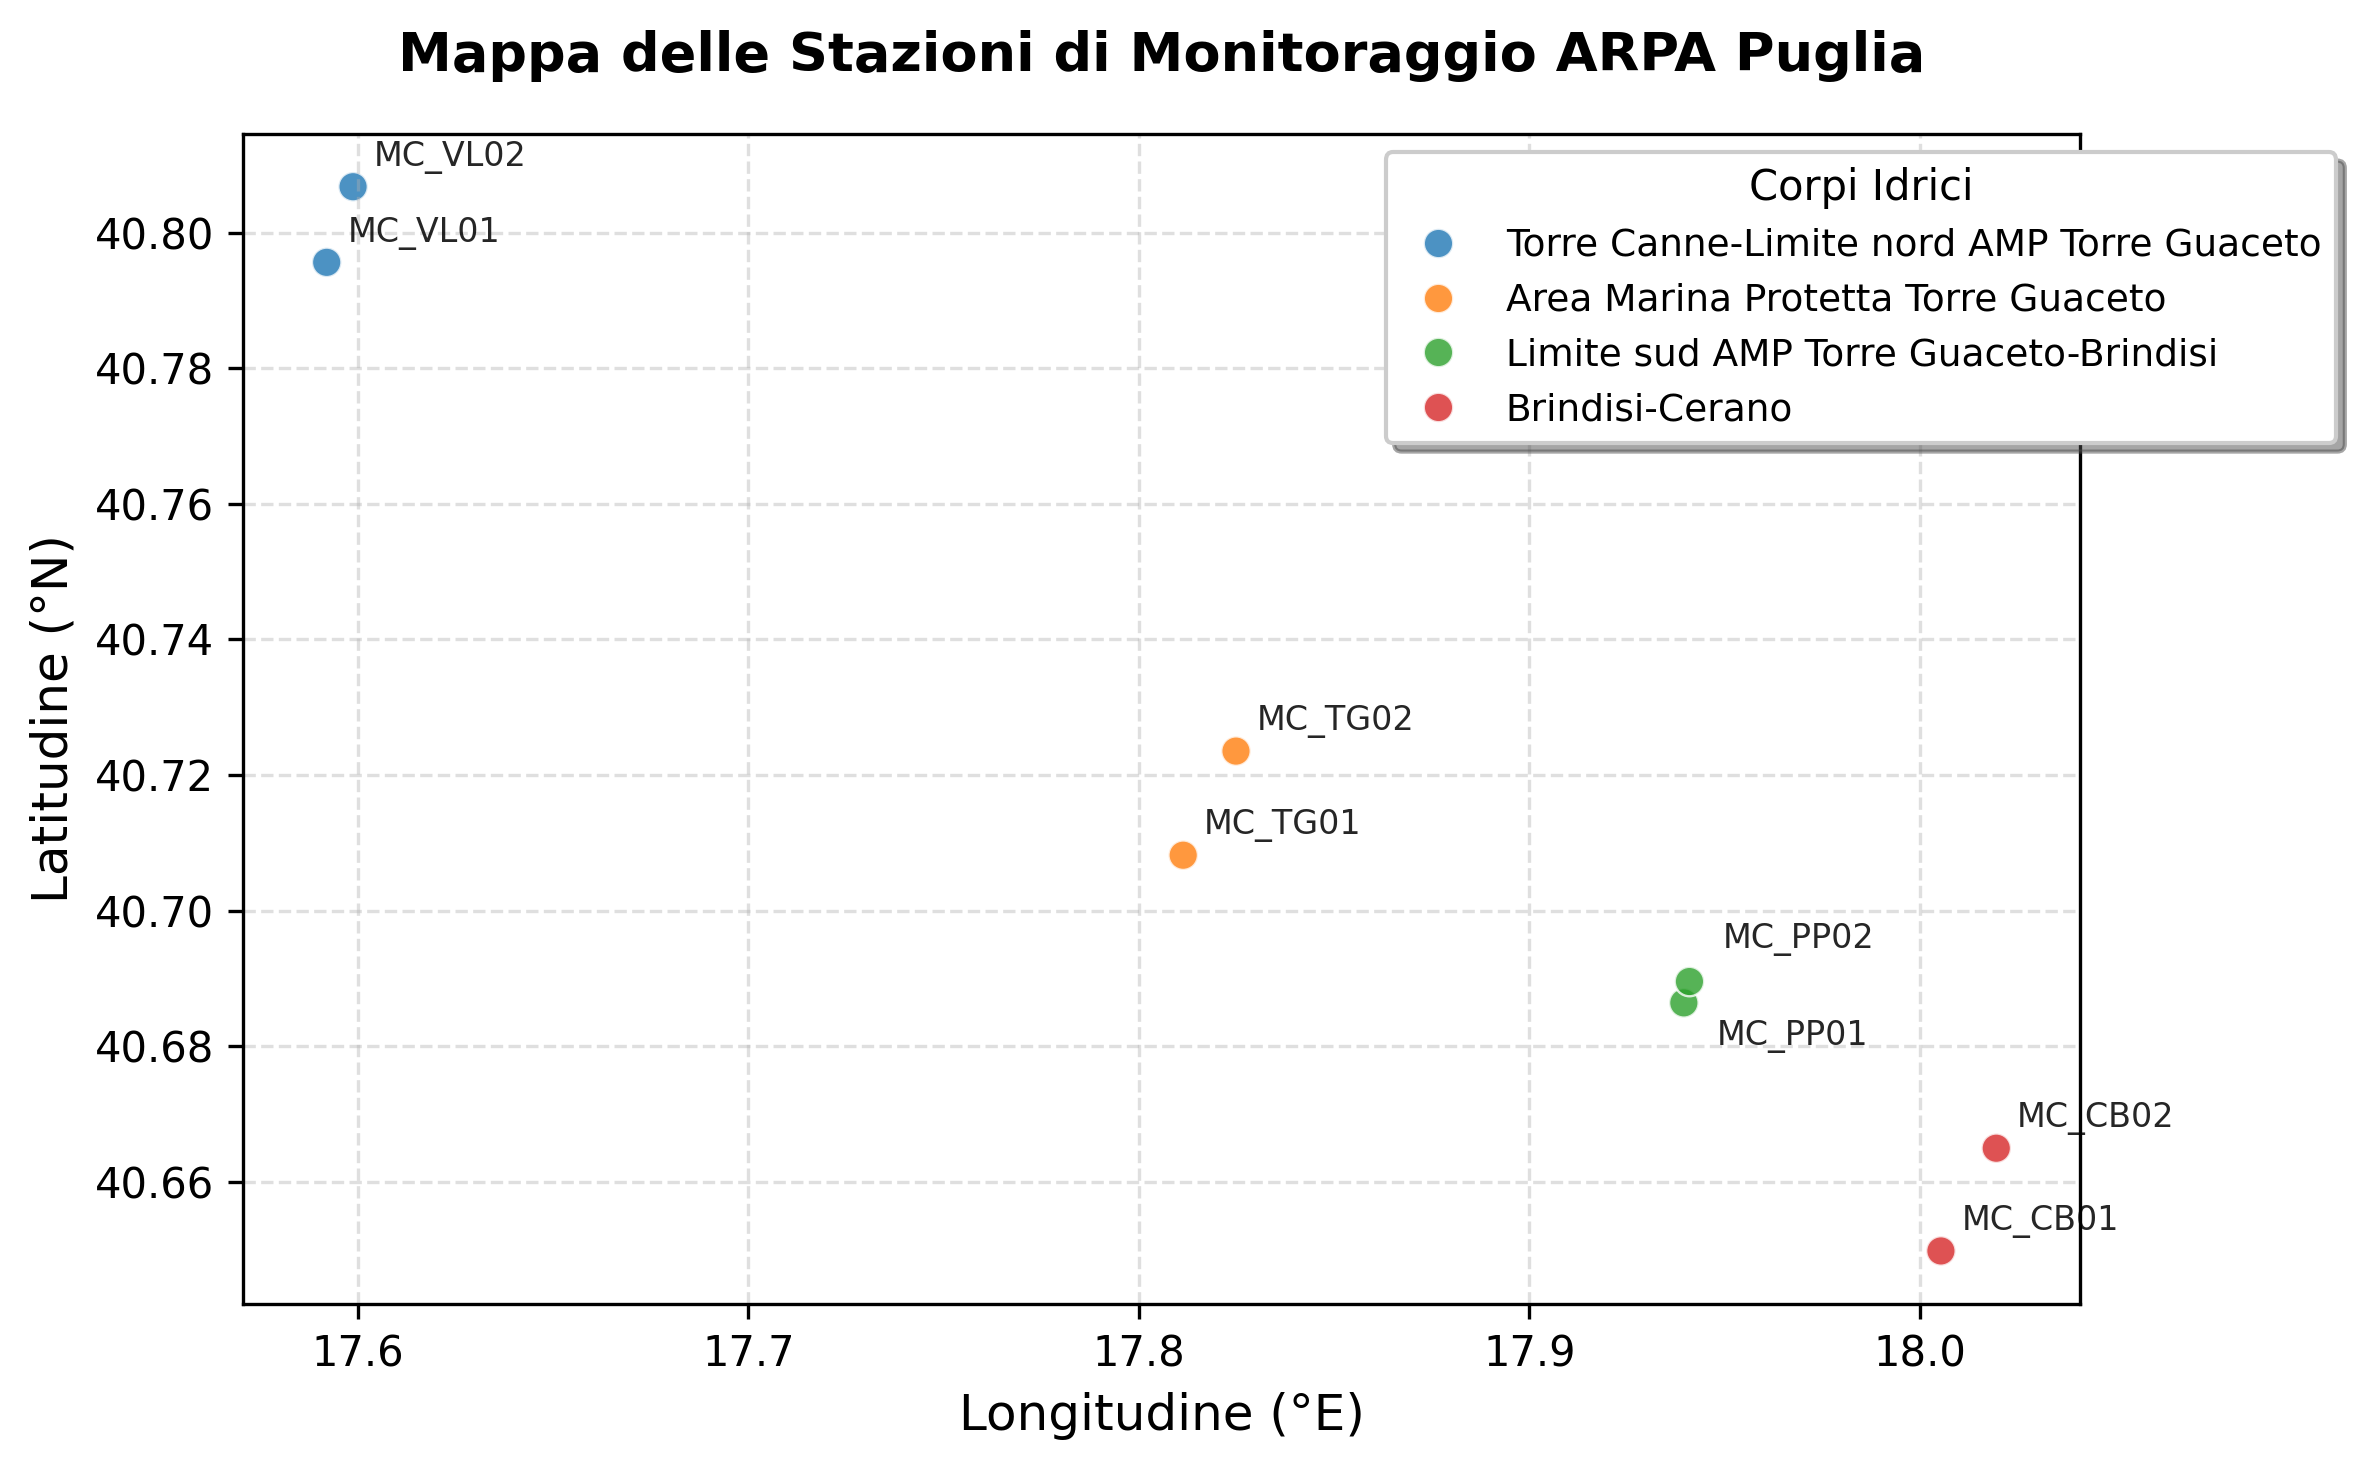

In [ ]:

#creo il grafico__ uso il comando fig,ax per avere un maggior controllo sul grafico e poter modificare facilmente le etichette, i titoli e la griglia
fig,ax = plt.subplots(figsize=(8,5), dpi=300)
#sns.scatterplot() crea ul grafico a dispersione 
    #assegno le coordinate agli assi
    #hue assegna un colore diverso a ciascun gruppo di punti in base alla colonna 'Corpo_idrico'
    #s=100 imposta la dimensione dei punti a 100
    #alpha=0.8 imposta la trasparenza dei punti a 0.8 (80% opaco, 20% trasparente) in modo da identificare meglio i punti sovrapposti
sns.scatterplot(x=long, y=lat, hue=df['Corpo_idrico'], s=50, alpha=0.8, ax=ax)

#aggiungo le etichette con il codice stazione per ogni punto 
    #df_plot.iterrows() è un comando Pandas che scorre la tabella riga per riga //ciclo for
    #idx è l'indice della riga, row è la riga stessa (puoi accedere ai valori con row['nome ccolonna'])
for idx, row in df.iterrows():
    stazione = row['Code_staz']
    if stazione == 'MC_PP02':
        offset=(8,8) #personalizzo la posizione delle etichette per evitare la sovrapposizione 
    elif stazione== 'MC_PP01':
        offset=(8,-10)
    else:
        offset=(5, 5)
    ax.annotate(stazione,(row['LONG_DD'], row['LAT_DD']),textcoords="offset points", xytext=offset, fontsize=8, alpha=0.85)
    #ax.annoate() aggiunge un'etichetta al grafico
            #stazine è il testo dell'etichetta (il codice stazione)
            #row['Code_staz'] è il valore della colonna 'Code_staz' per la riga corrente
            #(row['LONG_DD'], row['LAT_DD']) sono le coordinate del punto a cui associare l'etichetta
            #texcoords="offset points" dice di non sovrapporre il testo direttamente sul punto, ma di spostarlo di qualche pixel (offset) = xytext=() = spostamento 
            #ha='left' allinea il testo a sinistra del punto
plt.title('Mappa delle Stazioni di Monitoraggio ARPA Puglia', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Longitudine (°E)', fontsize=12)                                  #fontweight='bold' rende il testo in grassetto      #pad=15 aggiunge uno spazio tra il titolo e il grafico
plt.ylabel('Latitudine (°N)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.4)

#legenda: 
plt.legend(title='Corpi Idrici', title_fontsize=10, fontsize=9, loc='upper right', bbox_to_anchor=(1.15, 1), frameon=True, shadow=True, fancybox=True)
plt.tight_layout() #evita la sovrapposizione dei titoli e delle etichette del grafico, in modo che siano leggibili
plt.show()

### visualizzazione grafica con Cartopy

- Cartopy è una libreria Python progettata per la creazione di mappe e l'analisi di dati geografici e spaziali 
- Trasforma un grafico cartesiano in una carta geografica proiettata 



In [ ]:
# installa Cartopy
pip install cartopy 


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [58]:
#importa moduli di Cartopy per gestire la posizione geografica e le caratteristiche del territorio 
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from adjustText import adjust_text

c:\Users\sofia\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\cartopy\mpl\geoaxes.py:520: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  return super().draw(renderer=renderer, **kwargs)
c:\Users\sofia\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\cartopy\mpl\geoaxes.py:520: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  return super().draw(renderer=renderer, **kwargs)


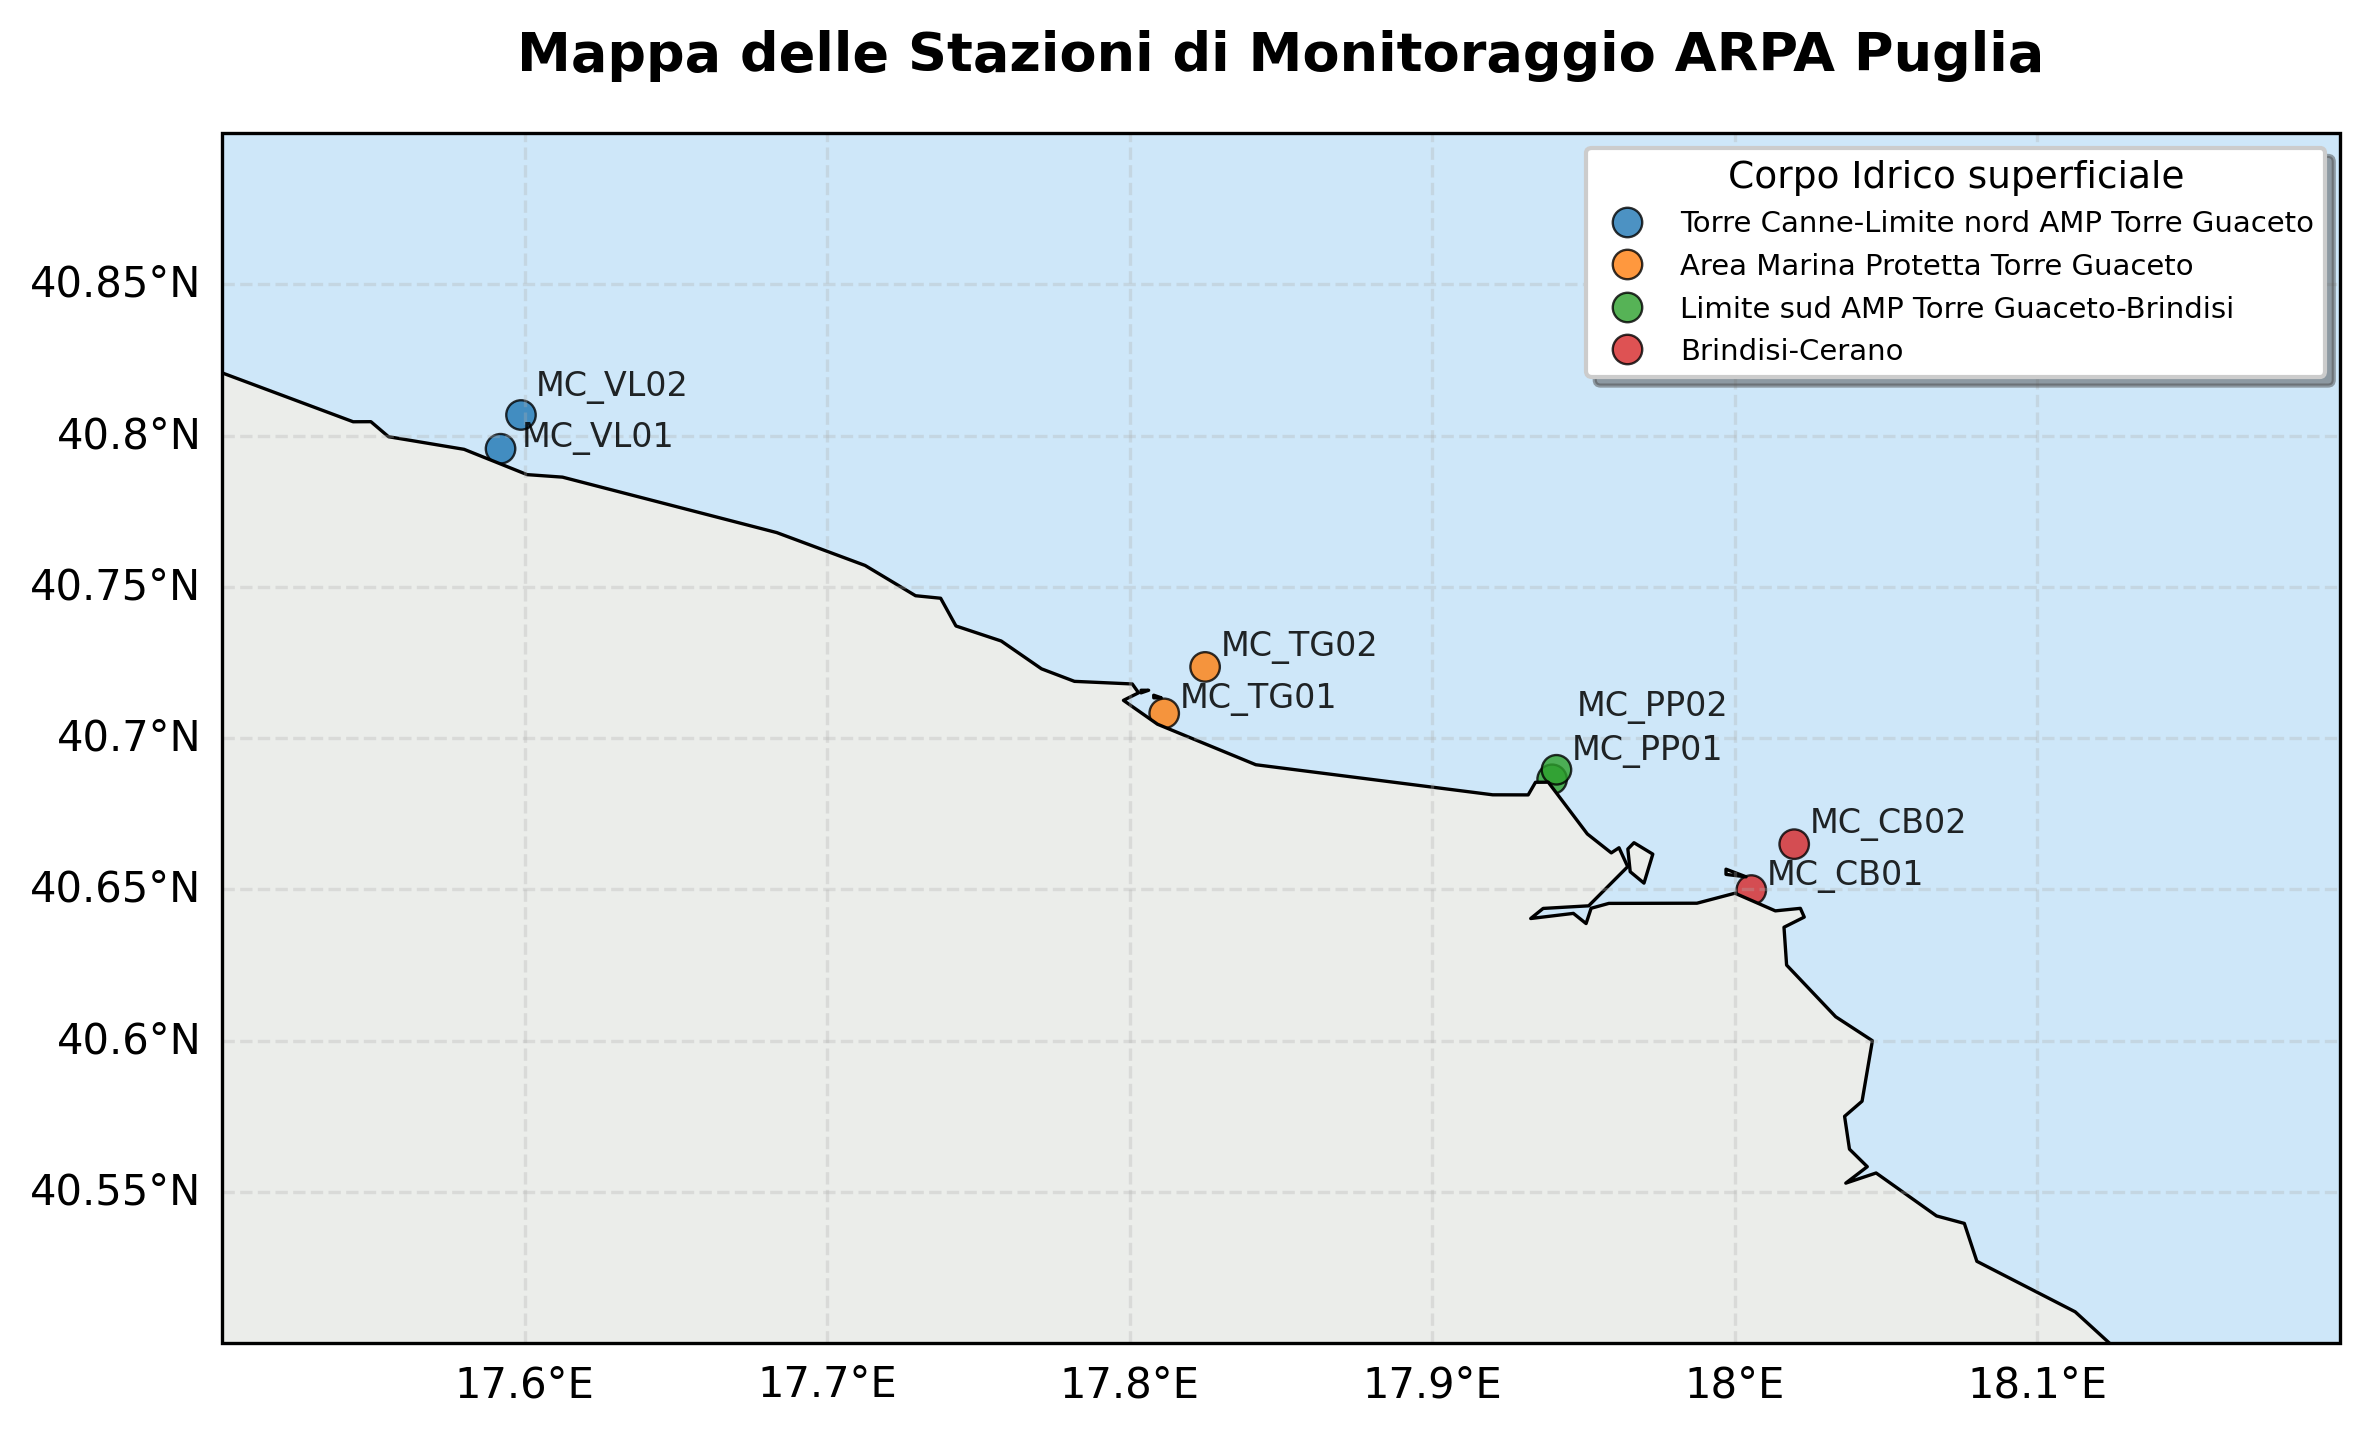

In [73]:
#modifico il grafico per aggiungere la mappa della Puglia e le caratteristiche geografiche del territorio

#creo un grafico non nel piano cartesiano ma un grafico gegrafico con poszione espressa in lat e long (PlateCarree)    
fig,ax=plt.subplots(figsize=(8,5), dpi=300, subplot_kw={'projection': ccrs.PlateCarree()}) 
    #subplot_kw={'projection': ccrs.PlateCarree()} crea un grafico con proiezione geografica (PlateCarree) che permette di visualizzare le coordinate geografiche in gradi decimali (latitudine e longitudine) in modo corretto sulla mappa

#imposto i confini della mappa (long min/max, lat min/max)
ax.set_extent([17.5,18.2, 40.5, 40.9], crs=ccrs.PlateCarree())
    #crs=ccrs.PlateCarree() indica che le coordinate scritte nelle parentesi [] sono in gradi decimali (lat e long) 

#impsta il colore dello sfondo come mare, tutto ciò che non sarà terraferma avrà questo colore (invece di usare cfeature.OCEAN che disegna il mare come un poligono, con questo comando il mare è tutto ciò che non è terraferma)
ax.set_facecolor("#BEE0F8C0") 

#usiamo questo comando per rendere la linea di costa ad alta risoluzione ('h') 
coastline = cfeature.GSHHSFeature(
    scale='h', 
    levels=[1], #indica quali tipi di confini disegnare (1=linee di costa dei continenti, 2=laghi, 3 isole nei laghi)
    facecolor="#ebedea",  # Colore terraferma
    edgecolor='black',    # Colore linea di costa
    linewidth=0.8
)
ax.add_feature(coastline)
ax.add_feature(cfeature.BORDERS.with_scale('10m'), linestyle=':') #disegna i confini regionali con linea tratteggiata

#tracciamo i punti di monitoraggio = Disegno il grafico a disperisione (scatterplot) 
sns.scatterplot(x=long, y=lat, hue=df['Corpo_idrico'], s=50, edgecolor='black', alpha=0.8, ax=ax, transform=ccrs.PlateCarree())
    #hue=df['Corpo_idrico'] assegna un colore diverso a ciascun gruppo di punti in base alla colonna 'Corpo_idrico'
    #s=60 imposta la dimensione dei punti 
    #ax=ax indica che il grafico a dispersione deve essere disegnato sul grafico geografico creato in precedenza
    #transform=ccrs.PlateCarree() indica che le coordinate dei punti sono in gradi decimali (lat e long)


#ora invece che usare ax.annotate all'interno del ciclo for per personalizzare la posizione delle etichette usiamo la libreria AdjustText
#tramite la funzione adjust_text() possiamo spostare automaticamente le etichette per evitarne la sovrapposizione 
    #questa libreria funziona leggendo un'intera lista di etichette (texts) analizzando dove si trovano i punti sulla mappa e calcolando autonomamente lo spazio necessario per spostarle senza farle sovrapporre 

texts= [] #creiamo una lista vuota per raccogliere le etichette da spostare
for idx, row in df.iterrows(): #ciclo che scorre la tabella riga per riga (idx è l'indice della riga, row è la riga stessa) 
                                        #puoi accedere ai valori con row['nome ccolonna'])
    stazione = row['Code_staz'] # assegna alla variabile stazione il valore della colonna 'Code_staz' per la riga corrente
    t = ax.text(row['LONG_DD'], row['LAT_DD'], stazione, fontsize=8, alpha=0.85, transform = ccrs.PlateCarree())
        #t è la nuova variabile che contiene l'etichetta creata con ax.text()
        #ax.text() aggiunge un'etichetta al grafico
            #stazione è il testo dell'etichetta
            #(row['LONG_DD'], row['LAT_DD']) sono le coordinate del punto a cui associare l'etichetta
            #transform=ccrs.PlateCarree() indica che le coordinate dei punti sono in gradi decimali (lat e long)
    texts.append(t) #prende l'etichetta creata (t) e la aggiunge alla lista texts=[]

#subito dopo il ciclo il comando adjust_text() prende la lista di etichette e le sposta nei punti liberi migliori
adjust_text(texts, ax=ax)
    #ax=ax indica che le etichette devono essere spostate sul grafico geografico creato in precedenza

#titolo
plt.title('Mappa delle Stazioni di Monitoraggio ARPA Puglia', fontsize=13, fontweight='bold', pad=15)

#griglia con le coordinate in gradi sui bordi 
gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.3)
gl.top_labels = False # nascondo le etichette in alto
gl.right_labels = False # nascondo le etichette sulla destra
                                            #loc la posizione dell'angolo in alto a dx   #facecolor= colore di sfondo    #framealpha=trasparenza del colore di sfondo  #frameon= True- ne disegna il bordo   #shadow= True aggiunge un'ombra    #fancybox= True- arrotonda gli angoli 
plt.legend(title='Corpo Idrico superficiale', title_fontsize=9, fontsize=7, loc='upper right', facecolor='white', frameon=True, shadow=True, fancybox=True)

plt.tight_layout() #evita la sovrapposizione dei titoli e delle etichette del grafico, in modo che siano leggibili
plt.show()

cerco di rendere lo sfondo realistico


In [68]:
#importa il modulo speciale di Cartopy per il caricamento di immagini satellitari dal web (come Google Maps, OpenStreetMap, ecc.) e visualizzarle come sfondo della mappa
import cartopy.io.img_tiles as cti 

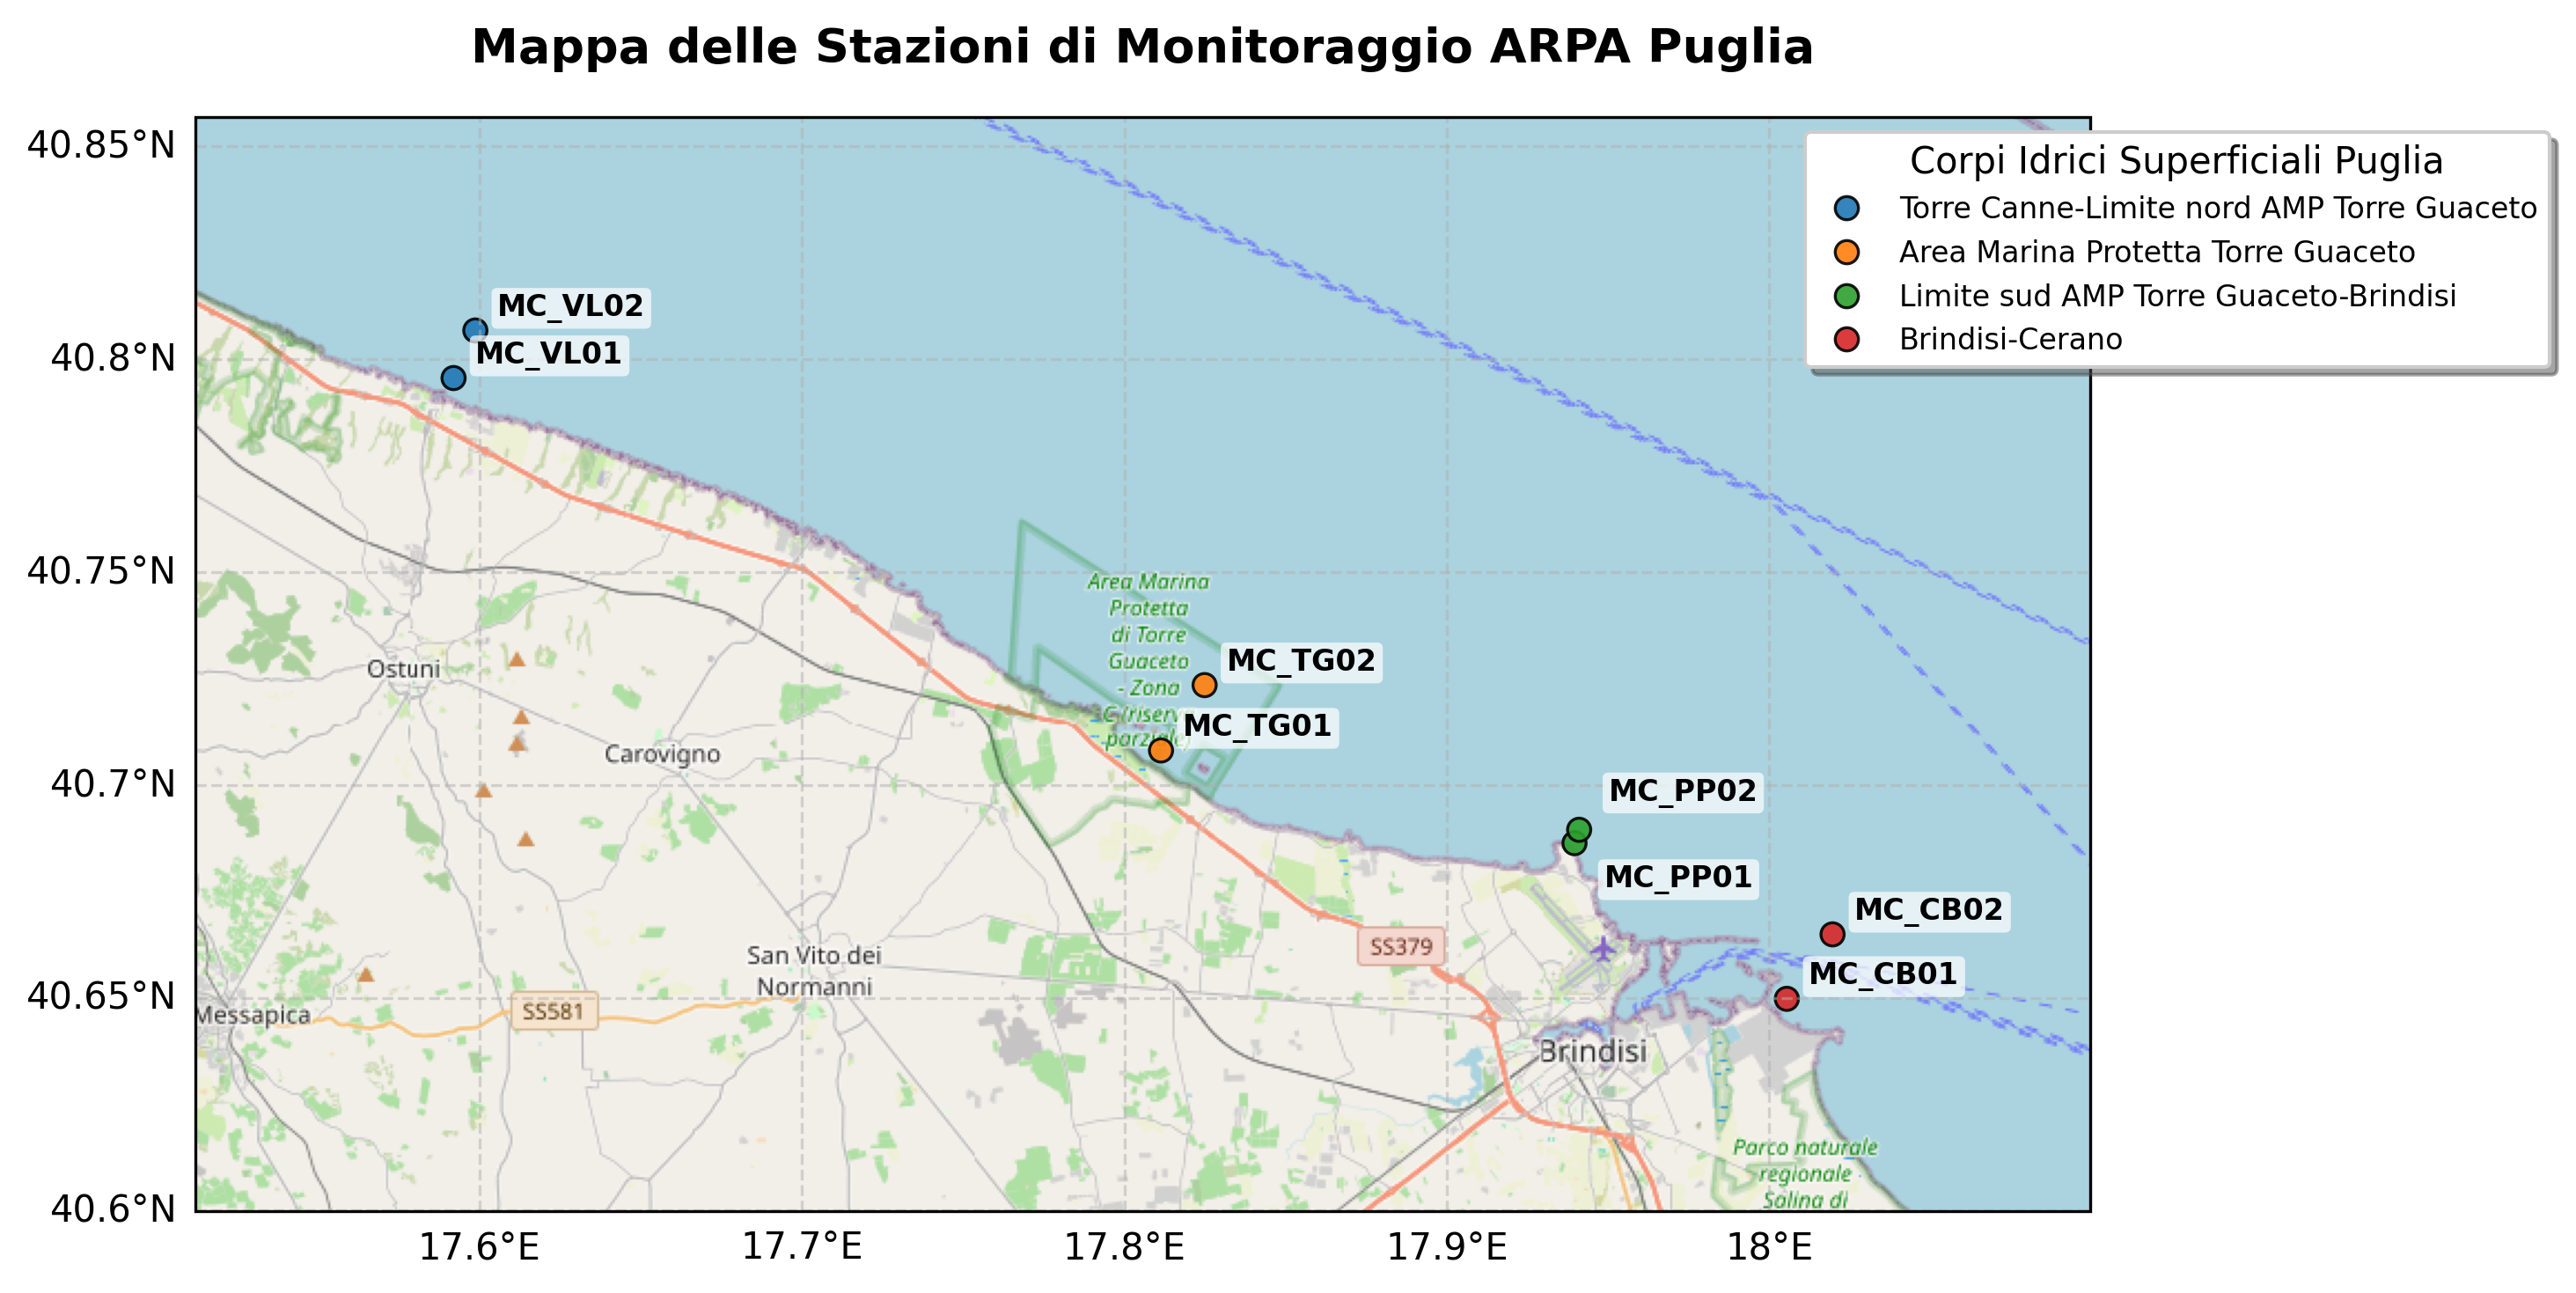

In [ ]:

# Scarichiamo le immagini di sfondo da OpenStreetMap 
osm_sfondo = cti.OSM()    #OSM = OpenStreetMap = è un provider = servizio web che fornisce le immagini cartografiche) 
                          #cti.OSM() è una funzione che fa sì che Python si colleghi al provider OSM per scaricare i riquadri di mappa corrispondenti alle zone del grafico per poi usarli come sfondo 

# Creiamo la figura usando la proiezione specifica del provider di mappe (osm_sfondo.crs)
fig, ax = plt.subplots(
    figsize=(10, 7), 
    dpi=300, 
    subplot_kw={'projection': osm_sfondo.crs} #le mappe Web non usano la classica griglia di gradi (plateCarrree()) ma una proiezione proiettata: Web Mercator (EPSG:3857) che permette di visualizzare le coordinate geografiche in gradi decimali (latitudine e longitudine) in modo corretto sulla mappa
)   #inserendo osm_sfondo.crs come proiezione, il grafico sarà allineato correttamente con le immagini di sfondo scaricate da OpenStreetMap

#Impostiamo lo zoom dell'area con un piccolo margine (0.08 sull'asse x e 0.05 sull'asse y) attorno ai punti decimali
    #a) definisco i valori min e max 
min_long, max_long = df['LONG_DD'].min() - 0.08, df['LONG_DD'].max() + 0.08
min_lat, max_lat = df['LAT_DD'].min() - 0.05, df['LAT_DD'].max() + 0.05
    #b) ax.set_extent() imposta i limiti della mappa    #crsc=ccrs.PlateCarree() indica che le coordinate scritte nelle parentesi [] sono in gradi decimali (lat e long)
ax.set_extent([min_long, max_long, min_lat, max_lat], crs=ccrs.PlateCarree())

# Aggiungiamo lo sfondo fotografico/cartografico 
    #ax.add_image() aggiunge le immagini scaricate (osm_sfondo) e le mette come sfondo
ax.add_image(osm_sfondo, 11)   #11 = zoom level = livello di dettaglio dell'immagine (valori tra 10 e 12 sono adatti x una mappa a scala regionale/provnciale)

# Disegniamo le stazioni con lo scatterplot di Seaborn
sns.scatterplot(
    data=df, 
    x='LONG_DD', 
    y='LAT_DD', 
    hue='Corpo_idrico', 
    s=40, 
    alpha=0.9, 
    edgecolor='black',  # Bordo nero ai punti per farli risaltare sullo sfondo
    linewidth=0.8,
    ax=ax,
    transform=ccrs.PlateCarree() #ccrs.PlateCarree() dice a Cartopy di proiettare i dati in gradi decimali 
)

# Etichette gestite per evitare sovrapposizioni nei punti vicini
for idx, row in df.iterrows():
    stazione = row['Code_staz']
    if stazione == 'MC_PP02':
        offset = (8, 8)
    elif stazione == 'MC_PP01':
        offset = (8, -12)
    else:
        offset = (6, 4)
        
    ax.annotate(   #ax.annoatate() aggiunge un'etichetta
        stazione,  #stazione è il testo dell'etichetta
        (row['LONG_DD'], row['LAT_DD']),   #coordinata del punto a cui è associata
        xytext=offset, #xytext=offset = spostamento dell'etichetta rispetto al punto (in pixel)
        textcoords="offset points", #textcoords="offset points" indica che le coordinate dell'etichetta sono relative al punto
        ha='left', #ha='left' allinea il testo a sinistra del punto
        fontsize=8, 
        fontweight='bold',     #bbox=dict() crea un rettangolo bianco semitrasparente attorno al testo dell'etichetta (x migliorarne la leggibilità)
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7), # Sfondo bianco semitrasparente al testo
        transform=ccrs.PlateCarree()  #boxstyle="round" crea un box con gli angoli arrotondati e "pad=0.2" aggiunge un po' di spazio tra il testo e il bordo del box
    )  #transform=ccrs.PlateCarree() indica che le coordinate dei punti sono in gradi decimali (lat e long)

#Titolo e Legenda                                                                 #pad è lo spazio tra il titolo e il grafico
plt.title('Mappa delle Stazioni di Monitoraggio ARPA Puglia', fontsize=13, fontweight='bold', pad=15) 

#gl = griglia   #ax.gridlines() crea una giglia    #draw_labels=True disegna le etichette dei gradi sugli assi della mappa   #linestyle='--' imposta il tratteggio della griglia   
gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.5)
gl.top_labels = False  # Nasconde le etichette della griglia sul bordo superiore
gl.right_labels = False  # Nasconde le etichette della griglia sul bordo destro

plt.legend(
    title='Corpi Idrici Superficiali Puglia', 
    title_fontsize=10, 
    fontsize=8, 
    loc='upper right', 
    bbox_to_anchor=(1.25, 1),  #box_to_anchor = box della legenda spostato a dx 
    frameon=True,  #frameon=True disegna il bordo della legenda
    shadow=True    #aggiunge un'ombra alla legenda
)

plt.tight_layout() 
plt.show()